<span style='font-size: 3rem;'><img src='./images/pyfgpu2_icon_256.png' style='height:6rem; vertical-align:middle;'/>&nbsp;FLAME GPU Fire Simulation Tutorial</span>

This is a tutorial for FLAME GPU. An open-source piece of software for the simulation of complex systems. It is domain-independent and can be used for any simulation that uses the idea of agent-based modelling. The agent-based modelling approach of describing individual behaviours and observing the emergent outputs enables FLAME GPU to be used for a wide range of examples such as flocking, cellular biology, and transportation. This tutorial focuses on a simple fire simulation model.

The purpose of the tutorial is to introduce the software and the modelling abstraction (API). The software aims to hide the underlying complexities of the GPU such as data structures and even parallelism. That said, there are important considerations when moving from a serial modelling methodology to a parallel one, which are presented and explained during this exercise.

FLAME GPU is developed in C++ but has a Python front end. This tutorial uses Python to define both the model description and the agent functions. There is an extensive set of user guidance and code documentation available for FLAME GPU which you can use alongside this tutorial for help: [https://docs.flamegpu.com/](https://docs.flamegpu.com/)

![Fire Simulation Example](./images/fire.gif)

## Background Information on Jupyter

For the purpose of this tutorial, the Jupyter notebook has been configured to work with FLAME GPU 2. The Jupyter notebook is a web based environment for interactive computing. It is capable of running code in a wide variety of programming languages. The notebook consists of cells which can be of type code or markdown (by default, new cells are created as code cells). You can execute the content of code cells by clicking the Run button. Cells which are actively running code will show a '*' symbol (or 'Play' icon in Colab) and cells which have completed will show a number indicating the position in which the cell was execute (or a green tick in Colab).

The notebook will guide you through the various commands required to run and edit a FLAME GPU 2 model using the python interface.

### Before Beginning

If using Google Colab, please ensure you have this notebook enabled with GPU before running (Runtime->Change runtime type). There are additional steps required for using this tutorial on colab below.

### Running your first code cell

The cell below is a simple example of a code cell. Clicking on the play button which appears when hovering over the cell with the mouse will run the code and you should see "Hello!" displayed beneath the code cell.

In [1]:
print("hello!")

hello!


## Using the Tutorial Within Google Colab

If initiating a colab notebook from GitHub the Python notebook will be loaded without any of the other files present within the Readme. The following cell will pull the files from GitHub so that they are local to the notebook.

In [2]:
import sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    '''
    !git init .
    !git remote add origin ADD_GH_REPO_URL_HERE
    !git pull origin main
    !git checkout main
    '''

Colab also has a known [bug](https://github.com/googlecolab/colabtools/issues/5155) with `ipympl` which is used for interactive plotting of the results. A work-around is to restart the kernel which you can do using the cell below.

In [3]:
if IN_COLAB:
    !pip install ipympl
    get_ipython().kernel.do_shutdown(restart=True)

Once the kernal has restarted the following command will ensure that custom widgets are enabled (a requirement of `ipympl` within Colab). *Note that the `IN_COLAB` variable will be lost due to the restart.*

In [4]:
import sys
if 'google.colab' in sys.modules:
    from google.colab import output
    output.enable_custom_widget_manager()

# Installation and Importing of FLAME GPU

The FLAME GPU python library can be installed through pip. This installs a binary release of the FLAME GPU 2 library. Run the cell below to install the FLAME GPU 2 library. If you are on a system where this has been pre-installed then the library will simply be imported.

In [5]:
# check if pyflamegpu is installed and if not install it
import importlib.util
if importlib.util.find_spec('pyflamegpu') is None:
    import sys
    !{sys.executable} -m pip install --extra-index-url https://whl.flamegpu.com/whl/cuda120/ pyflamegpu

# Import pyflamegpu and some other libraries we will use in the tutorial
import pyflamegpu
import pyflamegpu.codegen
import sys, random, math
import numpy as np
import matplotlib.pyplot as plt
import importlib

#set matplotlib backend to widget for some advanced plotting tools
%matplotlib widget

# import
import fire_visualiser

# reload local modules
importlib.reload(fire_visualiser)

<module 'fire_visualiser' from 'D:\\Code\\FLAMEGPU2-examples-n8cir\\examples\\fire\\fire_tutorial\\fire_visualiser.py'>

With the library installed, we need to configure the CUDA_PATH environment variable so the library can find the CUDA installation (Linux only as CUDA_PATH) will already be configured in Windows.

In [6]:
import platform
if platform.system() == 'Linux':
    %env CUDA_PATH=/usr/local/cuda

# The Fire Model

## Model Description
The fire model is a classical agent based model where a wildfire passes through a forest burning each tree it encounters. The purpose of the simulation is to show that the success of the wildfire critically depends on tree density in the forest. The variant of the model that we will work with in this tutorial is roughly equivalent to the 'Fire' model within NetLogo.

Within this model, an $N \times N$ grid is populated with trees, whose density is determined with a density parameter, $D$. At the beginning of the simulation, all cells located at $[0, i]$, where $0 \leq i < N$, are on `fire` and will spread to any `tree` cells in its Moore Neighbourhood. The wildfire continues to spread until it cannot reach anymore trees, at which point the simulation is complete.

![Fire Simulation Model Figure with citation below.](./images/fire_model_paper_figure.png)

Figure from: _Natural Science Models in Management: Opportunities and Challenges - Scientific Figure on ResearchGate. Available from: https://www.researchgate.net/figure/Forest-Fire-Model-with-Fire-Propagation-NetLogo-While-the-spread-of-innovation-and_fig1_241311601 [accessed 2 Sept 2026]_

## Model Implementation within FLAME GPU

Within this tutorial we will consider all cells as agents. This makes the most natural modelling sense and is easier for model visualisation. Each aspect of the model implementation will be explained as we progress through the tutorial.


# Model Parameters

Before defining the model in FLAME GPU we will first define some parameters of the model in Python. Additionally we will define some parameters which will be used later to configure distributions used when generating the initial state of the agent population.

In [7]:
# Model Parameters
DENSITY = 50
DIM = 128 # Dimensions of our 2D grid
SIMULATION_STEPS = 150

# Types each cell can be, 0 represents the 'empty' cell
TREE = 1
FIRE = 2
BURNT_TREE = 3

# Creating a Model

A FLAME GPU 2 model consists of:

1. An environment which holds global information related to the simulation such as constant properties.
2. A description of any messages which represent information to communicated between agents.
3. A description of agents which includes any state variables that they have and any functions which they can execute.
4. A control flow which describes the execution order of any functions within a single iteration of the simulation.
5. Initial population data and a simulation object which is used to instantiated to simulation object.

In the python build of FLAME GPU 2, all of these model elements are described through the python interface. A `ModelDescription` object acts as a parent/container for the various other components which make up the model. The following sections will describe how to create each of the above components and attach them to the `ModelDescription`. Each code cell defines a particular function. By defining functions rather than running the code directly, they can be updated individually and defined out of order. These functions are then all called in the correct order later in the tutorial.

The cell below creates and returns a `ModelDescription` object for the fire model.

In [8]:
def create_model():
    model = pyflamegpu.ModelDescription("fire")
    return model

# Defining the Environment

Within FLAME GPU the environment provides a mechanism to provide properties (variables) which can be accessed by all agents within a simulation. We previously defined a number of model parameters which will be used as initial values to environment properties in the cell below. It is important to define these as environment variables as Python global will not be available to agent functions which ultimately will be executed on the GPU device.

The cell below defines 3 different values for the agent status. These types define what state the agent is in, whether that is a tree, a tree on fire, or a burnt tree. The status value of `0` is left as the empty cell (see the [constant definitions](#model-parameters) in the previous section).

In [9]:
def define_environment(model):
    env = model.Environment()

    # Env properties
    env = model.Environment()
    env.newPropertyInt("TREE", TREE)
    env.newPropertyInt("FIRE", FIRE)
    env.newPropertyInt("BURNT_TREE", BURNT_TREE)

*Note: Although a default value for each property is set above, there are a number of ways that this can be overridden when creating the simulation object later. This can be useful if instantiating multiple simulations with differing environment properties.*

# Defining the Agents

A FLAME GPU model can consist of any number of agents. Our implementation requires only a single agent type that will represent a single cell of the Fire model. It therefore requires an `x` and `y` position (identifying the position within a regular 2D lattice) and a variable that holds information about the current `state` of the cell.

The agent definition below creates two agent functions (`writeStatus` and `updateStatus`) which we will define later in the notebook. The `newRTCFunction` method is used to specify these alongside the `pyflamegpu.codegen` module which which has a `translate` function. The `translate` function will take a pure python agent function (the format of which is described later) and transpile (the process of converting source code from one programming language to another) it to C++. The `newRTCFunction` call indicates that it is a **R**un**T**ime **C**ompilation function which will ensure the C++ source is compiled during model initialisation. This translation from Python to C++ for compilation is a requirement of FLAME GPU which uses NVIDIA CUDA to program the GPU device. All agent functions are compiled with a FLAME GPU device API which provides the mechanisms to query agent variables, messages and the environment. If you wish to see the transpiled C++ then you can `print` the output of the `translate` function and inspect this yourself. It has a very close resemblance to the underlying Python.

*Note: The definition of an agent does not actually require any specialisation in terms of what type of spatial domain an agent lives within. Agents may may exist within regular grid (as is the case of the Fire model), points within continuous space, a network, or any other domain abstraction. Rather than specialisation of agents, messages are instead specialised as a mechanism for agents to communicate within specific spatial constructs. The `x` and `y` variables exist so that the agent can communicate using the `Array2D` message specialism.*


In [10]:
def define_agents(model):
    agent = model.newAgent("agent")

    # Generic variables
    agent.newVariableFloat("x")
    agent.newVariableFloat("y")
    agent.newVariableInt("status")

    # Write and Update functions
    write_status_fn = agent.newRTCFunction(
    "write_status", pyflamegpu.codegen.translate(writeStatus)
    )
    update_status_fn = agent.newRTCFunction(
    "update_status", pyflamegpu.codegen.translate(updateStatus)
    )

*Note: The reason the $x$ and $y$ agent variables are `float` types is for local machine visualisation. These variables could be `ints` for this tutorial, but it is more common to use `float` types for agent movement variables in FLAME GPU.*

# Specifying the Functional Dependencies

A FLAME GPU simulation consists of the execution of a set of simulation steps. Each step has represents a single iteration of the simulation and is made up of a set of agent functions that are executed. The order of function execution creates a directed graph where functions depend on one another either;

1. Directly i.e. function 'B' has a dependency on function 'A' if it expects function 'A' to have executed first, or
2. Indirectly i.e. function 'B' has a dependency on function 'A' if function b reads a message which function A will output.

We have not specified any messages yet within our model but we can specify that our functions have a set of direct dependencies. This can be done either explicitly, by specifying the layers ([see docs](https://docs.flamegpu.com/guide/defining-execution-order/layers.html)) on which function will execute or by specifying the actual dependencies ([see docs](https://docs.flamegpu.com/guide/defining-execution-order/dependency-graph.html)). The later is preferable as greater care must be taken in the specification of layers to ensure that dependencies are respected.

The cell below defines a function to specify the functional dependencies. It also adds an execution root, which can be an agent function or in this case a submodel (described later) which is used to provide conflict free movement of the agents. The call to the `generateLayers` function freezes the dependencies and generates a graph of execution layers which respects the dependencies.

In [11]:
def define_dependencies(model):
    """
    Control Flow
    """
    agent = model.Agent("agent")
    update_status_fn = agent.Function("update_status")
    write_status_fn = agent.Function("write_status")

    # Define dependencies
    update_status_fn.dependsOn(write_status_fn)
    model.addExecutionRoot(write_status_fn)
    model.generateLayers()


# Defining Agent Functions

The Python agent functions referred to in our definition of the agent can now be specified. A limited subset of Python is supported which is restricted to Python features that can be easily transpiled to a C++ equivalent at runtime for compilation. For example Python functionality like generator expressions, arrays, dictionaries, etc. which do not have an obvious C++ equivalent are not permitted and will raise an exception. The subset of supported Python is referred to as *agent Python*. All agent Python functions are required to have a function decorator (i.e. `@pyflamegpu.agent_function`). A brief summary of agent Python functions is provided in the table below.

| Action | Code format | Notes
| :--- | :--- | :--- |
| Write a comment | `# This will be a comment` | |
| Declare a local variable | `variable_name = value` | *Variables do not require a type however if a specific type is required this can be inferred i.e.* `variable_name = float(value)`
| Read an agent variable | `variable_name = pyflamegpu.getVariableInt("variable_name")` | *Int can be replaced by other types and should match the type used when defining the agent variable in the AgentDescription.* |
| Get the value of an environment property of type Int | `pyflamegpy.environment.getPropertyInt("property_name")` | *Int can be replaced by other types.* |
| Iterate & access input messages | `for msg in message_in :` <br>&nbsp;&nbsp; `# Each message is now accessible inside this loop via msg` | `message_in.wrap(args...)` *can be used to proivide message wrapping. See the [docs](https://docs.flamegpu.com/guide/agent-functions/agent-communication.html#reading-messages) for more information.* |
| Read an input message variable value | `msg.getVariableInt("variable_name");` | *Must be called within a message loop. Int can be replaced by other types.*|
| Set an output message variable value | `pyflamegpu.message_out.setVariableInt("variable_name", value_to_set_variable_to)` | *Function definition must have specified a message output. Int can be replaced by other types.* |
| Generate a random float in the range [0,1) | `pyflamegpu.random.uniformFloat()` | *Other types of random distributions are described in the [docs].*(https://docs.flamegpu.com/guide/agent-functions/random-numbers.html).|
| Function leaves agent alive | `return pyflamegpu.ALIVE` | |
| Function kills agent | `return pyflamegpu.DEAD` | |

## Exercise 1: Simple Agent Messaging

Before the agent functions are implemented, it's important to consider how they will communicate and what each message will contain. In this fire model, we require each agent to write their status (whether they are a tree or a tree on fire, etc.) so that other agents can read and interpret this data. Therefore, we define a simple agent message that will be output at each position in the 2D grid, containing the status of each agent. The [FLAME GPU docs](https://docs.flamegpu.com/) have further information about [Agent Messaging](https://docs.flamegpu.com/guide/defining-messages-communication/index.html).

In [12]:
def define_message(model):
    msg_arr_2d = model.newMessageArray2D("msg_arr_2d")
    msg_arr_2d.newVariableInt("status")
    msg_arr_2d.setPersistent(True)
    msg_arr_2d.setDimensions(DIM, DIM)

### Exercise 1.1:

Below is a half-complete agent function used to write its status to a particular $(x,y)$ position in the grid. Using the agent function information outlined above and the [FLAME GPU docs](https://docs.flamegpu.com/), complete the `TODO` in the agent function (the solution can be found in the collapsed cell below).

In [13]:
@pyflamegpu.agent_function
def writeStatus(
    message_in: pyflamegpu.MessageNone, message_out: pyflamegpu.MessageArray2D
):
    # TODO:
    #       1. Set the messages index to be the current agent's position
    #       2. Write the value of the agent's status to the message
    return pyflamegpu.ALIVE

#### Solution to Exercise 1.1

In [14]:
@pyflamegpu.agent_function
def writeStatus(
    message_in: pyflamegpu.MessageNone, message_out: pyflamegpu.MessageArray2D
):
    message_out.setIndex(
        pyflamegpu.getVariableFloat("x"), pyflamegpu.getVariableFloat("y")
    )
    message_out.setVariableInt("status", pyflamegpu.getVariableInt("status"))
    return pyflamegpu.ALIVE

### Exercise 1.2:

Below is a half-complete agent function used to update an agents status in response to the messages provided by its nieghbouring agents. In this model, we want trees to start catching fire! Using the agent function information outlined above and the [FLAMEGPU docs](https://docs.flamegpu.com/), complete the `TODO` in the agent function (the solution can be found in the collapsed cell below). Some of the agent function has already been completed for you.

In [15]:
@pyflamegpu.agent_function
def updateStatus(
    message_in: pyflamegpu.MessageArray2D, message_out: pyflamegpu.MessageNone
):
    x = pyflamegpu.getVariableFloat("x")
    y = pyflamegpu.getVariableFloat("y")
    status = pyflamegpu.getVariableInt("status")

    # TODO:
    #       1. If I am a tree and one of my neighbours is on fire, I should catch fire
    #       2. Otherwise, if I am a tree on fire, I should become a burnt tree

    # Hint: I should read my neighbours' messages, which are broadcast in my adjacent cells...

    return pyflamegpu.ALIVE

#### Solution to Exercise 1.2:

In [16]:
@pyflamegpu.agent_function
def updateStatus(
    message_in: pyflamegpu.MessageArray2D, message_out: pyflamegpu.MessageNone
):
    x = pyflamegpu.getVariableFloat("x")
    y = pyflamegpu.getVariableFloat("y")
    status = pyflamegpu.getVariableInt("status")

    if status == pyflamegpu.environment.getPropertyInt("TREE"):
        for message in message_in(x, y):
            neighbour_status = message.getVariableInt("status")
            if neighbour_status == pyflamegpu.environment.getPropertyInt("FIRE"):
                pyflamegpu.setVariableInt(
                    "status", pyflamegpu.environment.getPropertyInt("FIRE")
                )
    elif status == pyflamegpu.environment.getPropertyInt("FIRE"):
        pyflamegpu.setVariableInt(
            "status", pyflamegpu.environment.getPropertyInt("BURNT_TREE")
        )

    return pyflamegpu.ALIVE

# Creation of Initial Population Data

The initial population of agents is created using an `AgentVector`. Individuals within the initial population are accessed by indexing into the vector and agent variables are set using the `setVariable...` function. Model variables have the same mapping as [they were defined](#Defining-the-Agents).

For our model, we require an initial population of trees that cover the 2D grid with a density of $D$ and a 'line' of fire at $x = 0$. To achieve this, we iterate over the `AgentVector` and set each $(x,y)$ position. To determine proper tree density, we take a random variable and check whether it is strictly less than $D$. If it is, we set this cell as a tree, otherwise it is empty. We also set the fire at its appropriate position in the grid. 

## Exercise 2: Creating the Initial Population

Complete the `TODO` lines in the cell below to successfully create an initial population of trees and fire. Some logic in the data creation has been completed for you. It may be useful to consult the [model parameters](#model-parameters) we defined earlier in the tutorial. The solution can be found in the collapsed cell below.

In [18]:
def initialise_population(model):
    t_pop = pyflamegpu.AgentVector(model.Agent("agent"), DIM * DIM)

    i = 0

    for x in range(DIM):
        for y in range(DIM):
            t = t_pop[i]

            t.setVariableFloat("x", x)
            t.setVariableFloat("y", y)

            if x == 0:
                # TODO: What status should I have...?
                pass
            elif np.random.randint(100) < DENSITY:
                # TODO: What status should I have...?
                pass
            else:
                # TODO: What status should I have...?
                pass

            i += 1

    return t_pop


### Exercise 2 Solution

In [19]:
def initialise_population(model):
    t_pop = pyflamegpu.AgentVector(model.Agent("agent"), DIM * DIM)

    i = 0

    for x in range(DIM):
        for y in range(DIM):
            t = t_pop[i]

            t.setVariableFloat("x", x)
            t.setVariableFloat("y", y)

            if x == 0:
                t.setVariableInt("status", FIRE)
            elif np.random.randint(100) < DENSITY:
                t.setVariableInt("status", TREE)
            else:
                t.setVariableInt("status", 0)

            i += 1

    return t_pop

# Create the Simulation

We have now defined the model, environment, agents, the functional dependencies and the initial population data for our model. The last step is to create a simulation object that will instantiate our model with the initial population data ready for execution. Before we do this however, we will need to define the messages that our agent functions have as their input and outputs.

The cell below creates the Cuda simulation ready for execution and defines the message types expected by our agent functions.

In [20]:
def initialise_simulation():
    global model    # make the model global so it can be accessed by other cells

    # create the model and define the environment, agents and dependencies
    model = create_model()
    define_environment(model)
    define_agents(model)
    define_message(model)
    define_dependencies(model)

    agent = model.Agent("agent")
    update_status_fn = agent.Function("update_status")
    write_status_fn = agent.Function("write_status")

    # Define the message input and output types for our functions
    write_status_fn.setMessageOutput("msg_arr_2d")
    update_status_fn.setMessageInput("msg_arr_2d")

    # create an initial population of agents
    init_pop = initialise_population(model)

    # create a CUDA simulation and set the initial data
    cuda_simulation = pyflamegpu.CUDASimulation(model)
    cuda_simulation.setPopulationData(init_pop)

    return cuda_simulation


# Running the Simulation

In order to run the simulation will call the `step` function a number of times. Each call will execute a single iteration of the Fire model. The `exportData` function can be used prior to simulation and after each step to output the complete state of the simulation including all agent variables. Whilst this is expense in terms of IO it will allow us to visualise the data or perform further analysis.

In this tutorial we perform a single simulation, FLAME GPU also supports ensembles of simulations which will allow multiple simulations to execute concurrently, potentially using multiple GPU devices (including over MPI). This can be very effective for parameter sweeps or optimisation.

The cell below defines a function to execute and export the simulation data. It also calls this function.

In [21]:
def execute_simulation():
    # delete previous data
    !rm -rf data
    !mkdir data

    cuda_simulation = initialise_simulation()
    # Log the initial state
    cuda_simulation.exportData(f"data/0.json")
    # simulate for number of steps and log the complete state
    for i in range(SIMULATION_STEPS):
        cuda_simulation.step()
        cuda_simulation.exportData(f"data/{i+1}.json")
    print("Simulation complete")

execute_simulation()

Simulation complete


# Visualising the Results

The Python module `fire_visualiser` has some helpful function to help in visualising the simulation output using MatplotLib. You can call the following;

1. `fire_visualiser.plot_state(step_no)` - This will plot a single state of the fire model.
2. `fire_visualiser.display_states(simulation_steps)` - This will create an interactive plot where a slider control the step number so that the model outputs at each step can be observed.
3. `fire_visualiser.animate_states(simulation_steps)` - This will create an animation from step 0 to `simulation_steps` to observe the simulations progression.

Try changing the value of `visualisation_mode` in the cell below to see the different visualisation options. If you wish to plot the results using a different visualisation option but have not re-run the simulation then then you can set `reload` to `False`.

*Note: There are much more efficient mechanisms for [visualisation](https://docs.flamegpu.com/guide/visualisation/index.html) of FLAME GPU simulation when working with a local GPU (i.e. a GPU on your own machine rather than in a Jupyter notebook). Additionally FLAME GPU has many options for [logging](https://docs.flamegpu.com/guide/visualisation/index.html) agent state variables using reduction operators rather than exporting the entire simulation state. Logging will perform the reductions on the GPU avoiding large data IO costs.*

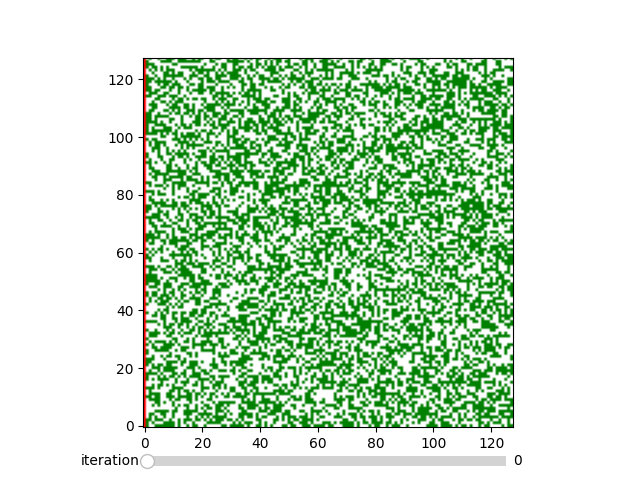

In [22]:
def visualise_model(visualisation_mode = 'display', reload=True): # valid visualisation_mode inputs are 'display', 'plot', 'animate'
    # reload data if reload is true
    if reload:
        fire_visualiser.load_data(SIMULATION_STEPS)

    # select which visualisation mode
    if visualisation_mode == 'plot':
        fire_visualiser.plot_state(0)
        fire_visualiser.plot_state(SIMULATION_STEPS)
    elif visualisation_mode == 'animate':
        fire_visualiser.animate_states(SIMULATION_STEPS)
    elif visualisation_mode == 'display':
        fire_visualiser.display_states(SIMULATION_STEPS)

# visualise the simulation
visualise_model(visualisation_mode = 'display')

# Conclusion

You have now completed a simple classical agent-based model simulating the movement of a wildfire across a forest. Hopefully, the flexible and logical flow of FLAME GPU model creation has been illustrated through this example and there are paradigms that can be transferred from this model to others. From here, there are numerous ways to extend the model's behaviour and functionality. Some example behaviours have been left below as an exercise:

## Exercise 3 (optional): Extending the Model

### Exercise 3.1

The first exercise would be extending the radius of the fire by increasing the number of messages read in the agent `updateStatus` function (see [Exercise 1.2](#exercise-12)). In a typical [Moore Neighbourhood](https://en.wikipedia.org/wiki/Moore_neighborhood), only the adjacent squares are considered. In this extension of the model, trial its behaviour when trees can catch fire from cells that are not adjacent to their current position.

### Exercise 3.2

Another exercise would be adding a _wind_ factor that can increase/decrease the spread of the fire depending on its position. For example, if there was a strong wind from the North, the spread of a fire at $(x_i, y_i)$ would be restricted when moving to $y_{i+1}$, but amplified when moving to $y_{i-1}$. This factor could be dictated as a [model parameter](#model-parameters) which is accessed through an [environment variable](#defining-the-environment). The probability of the fire spreading could be contingent on the strength of the wind from the North, South, East, and West.

### Exercise 3.3

The final exercise would be to create different variants of the tree type, which could burn at different rates. For example, the default tree could be left as is, with no discernable difference in its burn rate. But, two more different tree types `birch` and `spruce` could have lower / higher resistance to catching on fire, taking a higher number of steps before catching fire themselves. This could create a forest where some regions burn quicker/slower than others depending on the combination of tree types.